# Laboratory 2

## 1.4

### 1. (1D) Minimize $f(x)=x^4-4x^2+x$

Derivatives:

$$f'(x)=4x^3-8x+1,\qquad f''(x)=12x^2-8.$$

The critical points are the roots of $4x^3-8x+1=0$ (the polynomial has no rational roots, so they are computed numerically). The second-derivative test classifies each one: $f''>0$ local minimum, $f''<0$ local maximum.

The global minimum is the lowest of the local minima.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f   = lambda x: x**4 - 4*x**2 + x
fp  = lambda x: 4*x**3 - 8*x + 1
fpp = lambda x: 12*x**2 - 8

roots = np.sort(np.roots([4, 0, -8, 1]).real)

print(f"{'x*':>12} {'f(x*)':>12} {'f\'\'(x*)':>12}   classification")
for r in roots:
    kind = "local minimum" if fpp(r) > 0 else "local maximum"
    print(f"{r:12.6f} {f(r):12.6f} {fpp(r):12.6f}   {kind}")

x_global = roots[np.argmin(f(roots))]
print(f"\nGlobal minimum: x* = {x_global:.6f}, f(x*) = {f(x_global):.6f}")

          x*        f(x*)      f''(x*)   classification
   -1.472998    -5.444192    18.036663   local minimum
    0.126000     0.062748    -7.809487   local maximum
    1.346997    -2.618556    13.772824   local minimum

Global minimum: x* = -1.472998, f(x*) = -5.444192


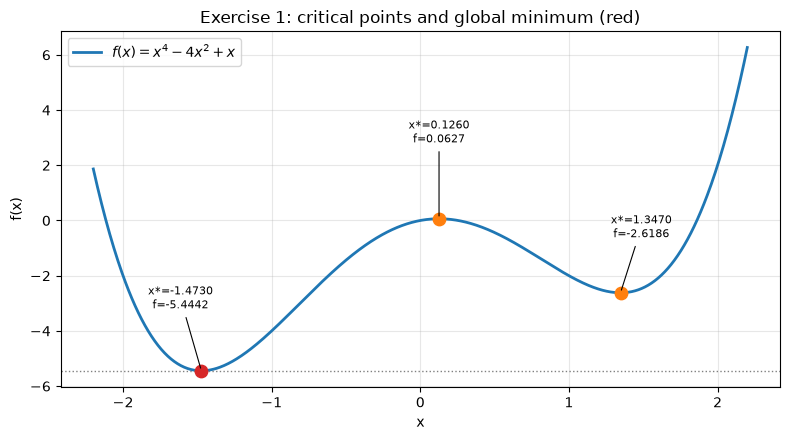

In [2]:
xs = np.linspace(-2.2, 2.2, 800)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, f(xs), lw=2, label=r"$f(x)=x^4-4x^2+x$")

offsets = [(-15, 45), (0, 55), (15, 40)]
for r, off in zip(roots, offsets):
    ax.scatter(r, f(r), s=80, zorder=3,
                color="tab:red" if r == x_global else "tab:orange")
    ax.annotate(f"x*={r:.4f}\nf={f(r):.4f}", (r, f(r)),
                textcoords="offset points", xytext=off, ha="center",
                fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.8))

ax.axhline(f(x_global), ls=":", color="gray", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Exercise 1: critical points and global minimum (red)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### 2. (2D) Minimize $f(x,y)=x^2+xy+y^2-4x-6y$

Gradient:

$$\nabla f(x,y)=\begin{bmatrix}2x+y-4\\ x+2y-6\end{bmatrix}.$$

Solving $\nabla f=0$:

$$\begin{cases}2x+y=4\\ x+2y=6\end{cases}\;\Longrightarrow\;(x^*,y^*)=\left(\tfrac{2}{3},\tfrac{8}{3}\right).$$

Hessian (constant):

$$H=\begin{bmatrix}2&1\\1&2\end{bmatrix},\qquad \lambda_1=1,\ \lambda_2=3>0.$$

$H$ is positive definite on all of $\mathbb{R}^2$, so the critical point is a strict local minimum and, since $f$ is a convex quadratic, it is also the **global minimum**. Minimum value: $f(2/3,8/3)=-28/3\approx-9.3333$.

In [3]:
grad = lambda x, y: np.array([2*x + y - 4, x + 2*y - 6])
f2   = lambda x, y: x**2 + x*y + y**2 - 4*x - 6*y

H = np.array([[2.0, 1.0], [1.0, 2.0]])
p = np.linalg.solve(H, np.array([4.0, 6.0]))

print("Critical point (x*, y*) =", p)
print("∇f(x*, y*) =", grad(*p))
print("Hessian:\n", H)
print("Eigenvalues:", np.linalg.eigvalsh(H))
print("D = f_xx f_yy - f_xy² =", np.linalg.det(H))
print(f"f(x*, y*) = {f2(*p):.6f}")

Critical point (x*, y*) = [0.66666667 2.66666667]
∇f(x*, y*) = [0. 0.]
Hessian:
 [[2. 1.]
 [1. 2.]]
Eigenvalues: [1. 3.]
D = f_xx f_yy - f_xy² = 2.9999999999999996
f(x*, y*) = -9.333333


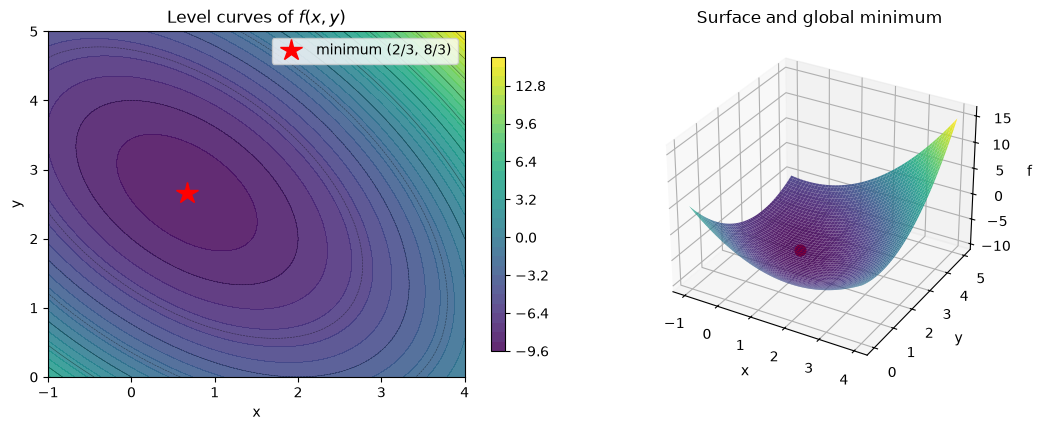

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

gx, gy = np.meshgrid(np.linspace(-1, 4, 150), np.linspace(0, 5, 150))
gz = f2(gx, gy)

fig = plt.figure(figsize=(11, 4.4))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(gx, gy, gz, levels=30, cmap="viridis", alpha=0.85)
ax1.contour(gx, gy, gz, levels=15, colors="k", linewidths=0.4, alpha=0.5)
ax1.plot(*p, "r*", ms=16, label=r"minimum $(2/3,\,8/3)$")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Level curves of $f(x,y)$")
ax1.legend(); fig.colorbar(cf, ax=ax1, shrink=0.85)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(gx, gy, gz, cmap="viridis", alpha=0.9, linewidth=0)
ax2.scatter(*p, f2(*p), color="red", s=60, zorder=5)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("f")
ax2.set_title("Surface and global minimum")

plt.tight_layout(); plt.show()

## Brief conclusions

- **1D:** there are three critical points: two local minima ($x\approx-1.4730$ and $x\approx1.3470$) and one local maximum ($x\approx0.1260$). The global minimum is $x^*\approx-1.4730$ with $f(x^*)\approx-5.4442$, since the function grows to $+\infty$ at both ends.
- **2D:** the only critical point is $(2/3,\,8/3)$; the constant positive-definite Hessian guarantees that it is the global minimum, with $f_{\min}=-28/3$.

---

## 2.2 Python exercise: pseudoinverse vs `lstsq`

### What problem are we solving?

Imagine that an unknown vector $x_{true}$ produces measurements $y$ through a matrix $A$:

$$y = A x_{true} + \text{noise}.$$

With noise, there is usually no vector that satisfies $Ax=y$ exactly. We therefore look for an estimate $\hat{x}$ whose prediction $A\hat{x}$ stays as close as possible to the measurements:

$$\hat{x}=\operatorname*{argmin}_x \|Ax-y\|_2^2.$$

The quantity $\|Ax-y\|_2$ is the length of the **residual**: the difference between the predicted and the observed measurements. Squaring it does not change which solution minimizes it.

We will obtain that estimate in two ways:

- `np.linalg.pinv(A) @ y` computes the Moore–Penrose pseudoinverse and multiplies it by $y$.
- `np.linalg.lstsq(A, y, rcond=None)[0]` asks NumPy directly for the least-squares solution. `[0]` selects the estimated vector from the results that the function returns.

In this exercise both approaches should give practically the same vector. `lstsq` is usually the direct option for solving the problem; `pinv` helps to connect the computation with the pseudoinverse.

### What do $m>n$ and $m<n$ mean?

The matrix $A$ has size $(m,n)$: it has $m$ rows (measurements) and $n$ columns (unknown coefficients).

- **$m>n$ (overdetermined):** there are more measurements than unknowns. If the columns of $A$ are independent, there is a unique best least-squares solution. Because of the noise, the residual is usually nonzero.
- **$m<n$ (underdetermined):** there are fewer measurements than unknowns. Many solutions can produce the same measurements, so the data are not enough to identify the original vector. `pinv` and `lstsq` choose the shortest solution, called the **minimum-norm solution**.

The experiment creates a known $x_{true}$, generates noisy measurements, and compares how close each estimate is to that vector and how well each one fits the measurements. Here we know the true answer because it is a simulation; in a real problem we usually do not.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

SIGMA = 0.05


def run_case(m, n, seed):
    # The fixed seed makes the random example reproducible.
    rng = np.random.default_rng(seed)

    # Build a random matrix and a known true response.
    A = rng.standard_normal((m, n))
    x_true = rng.standard_normal(n)
    # The measurements are A @ x_true plus random noise.
    y = A @ x_true + SIGMA * rng.standard_normal(m)

    # Solve the same problem with two NumPy routines.
    x_pinv = np.linalg.pinv(A) @ y
    x_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]

    def relative_error(x):
        # Relative coefficient error: 0 means perfect recovery.
        return np.linalg.norm(x - x_true) / np.linalg.norm(x_true)

    def residual(x):
        # Measurement mismatch: length of A @ estimate - y.
        return np.linalg.norm(A @ x - y)

    return {
        "m": m, "n": n,
        "A": A, "x_true": x_true, "y": y,
        "x_pinv": x_pinv, "x_lstsq": x_lstsq,
        "rel_pinv": relative_error(x_pinv),
        "rel_lstsq": relative_error(x_lstsq),
        "res_pinv": residual(x_pinv),
        "res_lstsq": residual(x_lstsq),
    }


cases = {
    "m > n": run_case(80, 20, seed=1),
    "m < n": run_case(20, 80, seed=2),
}

print(f"{'case':<6} {'method':<8} {'rel. error':>12} {'residual':>12}")
print("-" * 42)
for name, r in cases.items():
    print(f"{name:<6} {'pinv':<8} {r['rel_pinv']:12.3e} {r['res_pinv']:12.3e}")
    print(f"{'':<6} {'lstsq':<8} {r['rel_lstsq']:12.3e} {r['res_lstsq']:12.3e}")

print("\nMaximum difference between pinv and lstsq:")
for name, r in cases.items():
    diff = np.linalg.norm(r["x_pinv"] - r["x_lstsq"])
    print(f"  {name}: {diff:.2e}")


case   method     rel. error     residual
------------------------------------------
m > n  pinv        4.471e-03    4.148e-01
       lstsq       4.471e-03    4.148e-01
m < n  pinv        8.928e-01    4.759e-14
       lstsq       8.928e-01    4.578e-14

Maximum difference between pinv and lstsq:
  m > n: 1.01e-14
  m < n: 5.46e-15


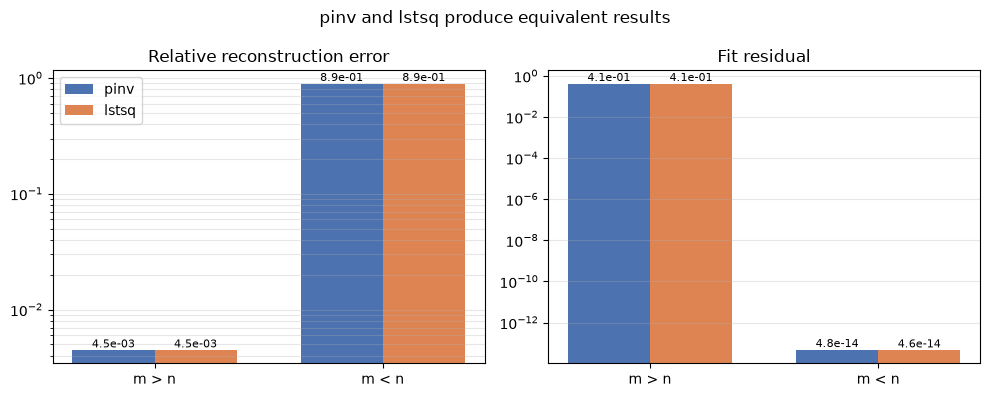

In [6]:
names = list(cases.keys())
pos = np.arange(len(names))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, key, title in zip(
    axes,
    ["rel", "res"],
    ["Relative reconstruction error", "Fit residual"],
):
    values_pinv = [cases[k][key + "_pinv"] for k in names]
    values_lstsq = [cases[k][key + "_lstsq"] for k in names]

    ax.bar(pos - width / 2, values_pinv, width,
            label="pinv", color="#4C72B0")
    ax.bar(pos + width / 2, values_lstsq, width,
            label="lstsq", color="#DD8452")

    ax.set_xticks(pos, ["m > n", "m < n"])
    # The logarithmic scale allows comparing very different values.
    ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", which="both", alpha=0.3)

    for x, v in zip(pos - width / 2, values_pinv):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)
    for x, v in zip(pos + width / 2, values_lstsq):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)

axes[0].legend()
fig.suptitle("pinv and lstsq produce equivalent results")
fig.tight_layout()
plt.show()


**How to read this figure:** each group compares blue (`pinv`) and orange (`lstsq`) for one matrix shape. The left panel shows the relative error; the right one, the residual. The vertical axis is logarithmic: moving up one step multiplies the value rather than adding a fixed amount. Bars of almost equal height indicate that the two methods agree. In the $m<n$ case a tiny residual and a large relative error can occur at the same time: fitting the measurements well does not guarantee recovering the true coefficients.


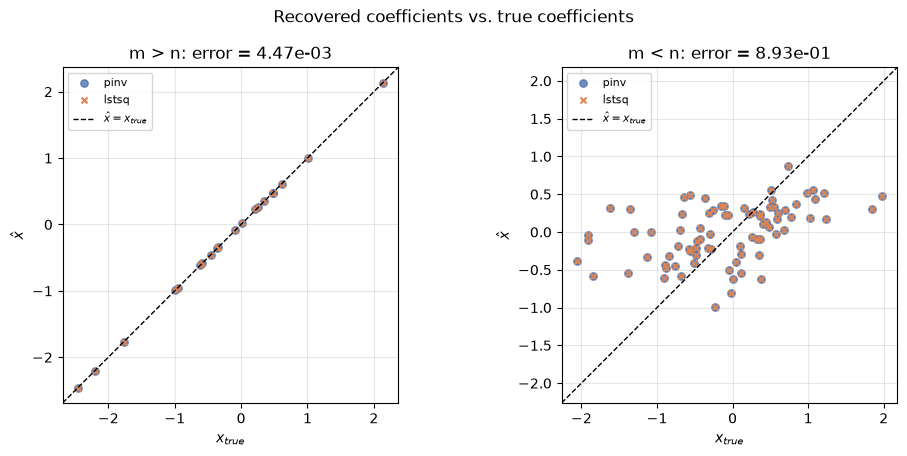

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

for ax, (name, r) in zip(axes, cases.items()):
    ax.scatter(r["x_true"], r["x_pinv"], s=28, alpha=0.8,
                label="pinv", color="#4C72B0")
    ax.scatter(r["x_true"], r["x_lstsq"], s=18, marker="x",
                label="lstsq", color="#DD8452")

    minimum = min(r["x_true"].min(), r["x_pinv"].min(), r["x_lstsq"].min())
    maximum = max(r["x_true"].max(), r["x_pinv"].max(), r["x_lstsq"].max())
    margin = 0.05 * (maximum - minimum)

    ax.plot([minimum - margin, maximum + margin],
            [minimum - margin, maximum + margin],
            "k--", lw=1, label=r"$\hat{x}=x_{true}$")

    ax.set_xlim(minimum - margin, maximum + margin)
    ax.set_ylim(minimum - margin, maximum + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x_{true}$")
    ax.set_ylabel(r"$\hat{x}$")
    ax.set_title(f"{name}: error = {r['rel_pinv']:.2e}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Recovered coefficients vs. true coefficients")
fig.tight_layout()
plt.show()



---

## 3.1 Exercise: deconvolution and instability

### 1. What do we want to do?

We have an original image $X$, we blur it and observe a version $y$. The model is

$$y=Ax+e,$$

- $x$ is the image stored as a long vector (`X.ravel()`).
- $A$ is the blur operator: it transforms the image into its blurred version.
- $e$ is noise added to the measurement.
- $y$ is the blurred image we observe (possibly with noise).

Applying the blur is the **forward problem**. Recovering the original image from the blurred image is **deconvolution**, or the inverse problem. We will first test the pseudoinverse with clean and with noisy data to see why inverting a blur can be unstable.

### 2. Data and blur operator

We use a grayscale image of $48\times48$ pixels, scaled to the range [0,1], and a Gaussian kernel of $9\times9$ with `sigma=1.5`. At the borders we use reflection (`boundary="symm"`).

We build the matrix $A$ by applying the blur to test images with a single pixel turned on. Each result is a column of $A$. This allows the blur to be represented as a matrix multiplication, although building and storing that matrix is expensive; that is why we use a small image.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from skimage import data, transform
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Prepare the image: grayscale, small size and intensities between 0 and 1.
X = data.camera().astype(float) / 255.0
X = transform.resize(X, (48, 48), anti_aliasing=True)
X = X / X.max()

h, w = X.shape           # image height and width
N = h * w                # total number of pixels
print(f"Image: {h}x{w} = {N} pixels; range [{X.min():.2f}, {X.max():.2f}]")


def gaussian_kernel(size=9, sigma=1.5):
    """Create a normalized Gaussian kernel (the weights sum to 1)."""
    radius = size // 2
    coords = np.arange(-radius, radius + 1)
    xx, yy = np.meshgrid(coords, coords)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()


K = gaussian_kernel(size=9, sigma=1.5)


def blur_image(image):
    """Apply the blur without changing the image size."""
    return convolve2d(image, K, mode="same", boundary="symm")


# Build A: each column is the blur of an image with a single pixel turned on.
A = np.empty((N, N))
for pixel_index in range(N):
    impulse = np.zeros((h, w))
    impulse.flat[pixel_index] = 1.0
    A[:, pixel_index] = blur_image(impulse).ravel()

print(f"Shape of A: {A.shape}; number of entries: {A.size:,}")
print(f"Symmetry error max|A-A.T|: {np.abs(A - A.T).max():.2e}")
print(f"Sum of the kernel weights: {K.sum():.6f}")


Image: 48x48 = 2304 pixels; range [0.02, 1.00]
Shape of A: (2304, 2304); number of entries: 5,308,416
Symmetry error max|A-A.T|: 2.78e-17
Sum of the kernel weights: 1.000000



Each column of $A$ shows how a single pixel is spread among its neighbors when it is blurred. Once $A$ is built, the full blur of the image is computed as `A @ x`.

### Why do we use the SVD to compute the pseudoinverse?

The SVD factorizes the matrix as $A=U\Sigma V^\top$. From it we obtain the pseudoinverse $A^\dagger=V\Sigma^{-1}U^\top$, which is exactly the operation performed by `np.linalg.pinv(A)`.

We compute it only once because in this section we apply the pseudoinverse many times (several data sets and several noise levels). Reusing the SVD avoids repeating that expensive computation. It also gives us the singular values, which we will use to explain why the noise is amplified. So **the reconstruction uses the pseudoinverse; the SVD is an efficient way to compute it and to study the instability**.


In [9]:
# Factor A only once. NumPy returns A = U @ diag(s) @ Vt.
# We will reuse these factors to invert several measurement vectors.
U, s, Vt = np.linalg.svd(A, full_matrices=False)


def pseudoinverse_apply(measurements):
    """Compute A^dagger @ measurements using the SVD already computed."""
    # U.T @ measurements: express the data in the directions of U.
    # Divide by s: invert the effect of the blur in each direction.
    # Vt.T @ ...: return to the pixel coordinates.
    return Vt.T @ ((U.T @ measurements) / s)


# Original vector and blurred measurement without noise.
x = X.ravel()
y = A @ x

# Experiment 1: add noise to the measurement AFTER the blur.
SIGMA_ETA = 0.005
rng = np.random.default_rng(1)  # fixed seed: reproducible results
noise = SIGMA_ETA * rng.standard_normal(N)
y_noisy = y + noise
# The same noisy measurement, under the name used in the text of Section 4.3.
y_eta = y_noisy

# Apply the pseudoinverse to clean and to noisy data.
x_recovered_clean = pseudoinverse_apply(y)
x_recovered_noisy = pseudoinverse_apply(y_noisy)

# Experiment 2: add the same noise to the image BEFORE the blur.
x_noisy_before_blur = x + noise
y_from_noisy_image = A @ x_noisy_before_blur
x_recovered_before_blur = pseudoinverse_apply(y_from_noisy_image)

# Numerical summary of how much each case is altered.
print(f"Condition number of A: {s[0] / s[-1]:.2e}")
print(f"Relative error added to y: {np.linalg.norm(noise) / np.linalg.norm(y):.3e}")
print(f"Amplification when inverting noise in y: "
      f"{np.linalg.norm(x_recovered_noisy - x) / np.linalg.norm(noise):.2e}x")
print(f"Maximum error, clean case: "
      f"{np.max(np.abs(x_recovered_clean - x)):.2e}")
print(f"Maximum error, noise before the blur: "
      f"{np.max(np.abs(x_recovered_before_blur - x_noisy_before_blur)):.2e}")

# Compare quality metrics against the original image.
examples = [
    ("blurred measurement y", y),
    ("pseudoinverse, clean", x_recovered_clean),
    ("measurement with noise", y_noisy),
    ("pseudoinverse, noisy", x_recovered_noisy),
    ("original image + noise", x_noisy_before_blur),
    ("inverting pre-blur noise", x_recovered_before_blur),
]
print(f"\n{'Result':27s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 47)
for label, vector in examples:
    image = vector.reshape(h, w)
    score_psnr = psnr(X, image, data_range=1.0)
    score_ssim = ssim(X, image, data_range=1.0)
    print(f"{label:27s} {score_psnr:10.2f} {score_ssim:7.3f}")


Condition number of A: 2.44e+08
Relative error added to y: 7.962e-03
Amplification when inverting noise in y: 4.38e+06x
Maximum error, clean case: 1.73e-09
Maximum error, noise before the blur: 1.25e-09

Result                       PSNR (dB)    SSIM
-----------------------------------------------
blurred measurement y            23.49   0.812
pseudoinverse, clean            187.72   1.000
measurement with noise           23.45   0.804
pseudoinverse, noisy            -86.90   0.000
original image + noise           45.94   0.993
inverting pre-blur noise         45.94   0.993


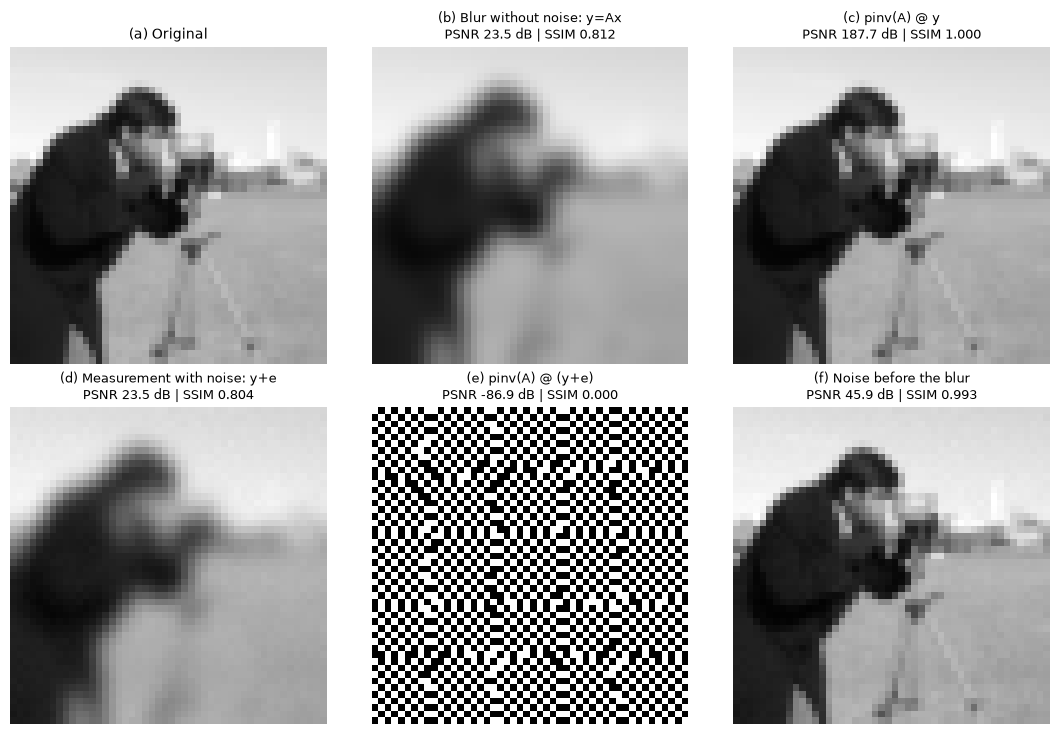

In [10]:
# Prepare the six comparison panels.
panels = [
    ("(a) Original", X, None),
    ("(b) Blur without noise: y=Ax", y.reshape(h, w), y),
    ("(c) pinv(A) @ y", x_recovered_clean.reshape(h, w), x_recovered_clean),
    ("(d) Measurement with noise: y+e", y_noisy.reshape(h, w), y_noisy),
    ("(e) pinv(A) @ (y+e)", x_recovered_noisy.reshape(h, w), x_recovered_noisy),
    ("(f) Noise before the blur", x_recovered_before_blur.reshape(h, w),
     x_recovered_before_blur),
]

fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, image, vector) in zip(axes.ravel(), panels):
    # Clipping only affects the visualization; it does not modify the computations or the metrics.
    ax.imshow(np.clip(image, 0, 1), cmap="gray", vmin=0, vmax=1)
    if vector is None:
        ax.set_title(title, fontsize=10)
    else:
        image_vector = vector.reshape(h, w)
        score_psnr = psnr(X, image_vector, data_range=1.0)
        score_ssim = ssim(X, image_vector, data_range=1.0)
        ax.set_title(f"{title}\nPSNR {score_psnr:.1f} dB | SSIM {score_ssim:.3f}",
                     fontsize=9)
    ax.axis("off")

fig.tight_layout()



**Figure 1: how to read it.** The six panels compare the original image, the blurred measurements and the reconstructions with the pseudoinverse. PSNR and SSIM are measures of similarity to the original image: a larger value usually indicates a better reconstruction.

- **(a)** Original image, used as the reference.
- **(b)** Image after the blur, without noise.
- **(c)** Result of applying the pseudoinverse to clean data: it recovers almost the whole image.
- **(d)** Blurred measurement with noise added after the blur. The noise is small and is barely visible here.
- **(e)** Reconstruction of (d): the noise is amplified and dominates the result. The clipping to [0,1] is only for displaying the image; the metrics use the unclipped values.
- **(f)** Control: noise was added to the image before the blur. Inverting recovers the image with approximately that same noise.

The most important comparison is **(e) versus (f)**: the pseudoinverse amplifies the noise a lot when it is added after the blur.



### 3. Why is the noise amplified?

The blur greatly reduces certain details of the image. To undo it, the pseudoinverse must amplify those weak directions. The problem is that it also amplifies the noise that lies in them.

The SVD helps to see this: $A=U\Sigma V^\top$, and the diagonal entries $s_i$ of $\Sigma$ indicate how much the blur preserves each direction. To invert, we divide by $s_i$. If $s_i$ is very small, dividing by it magnifies any error. The condition number $s_{max}/s_{min}$ summarizes the worst case of that amplification.

It is not necessary to know the SVD in order to use `np.linalg.pinv`; we show it here to explain why the pseudoinverse is unstable in this problem.


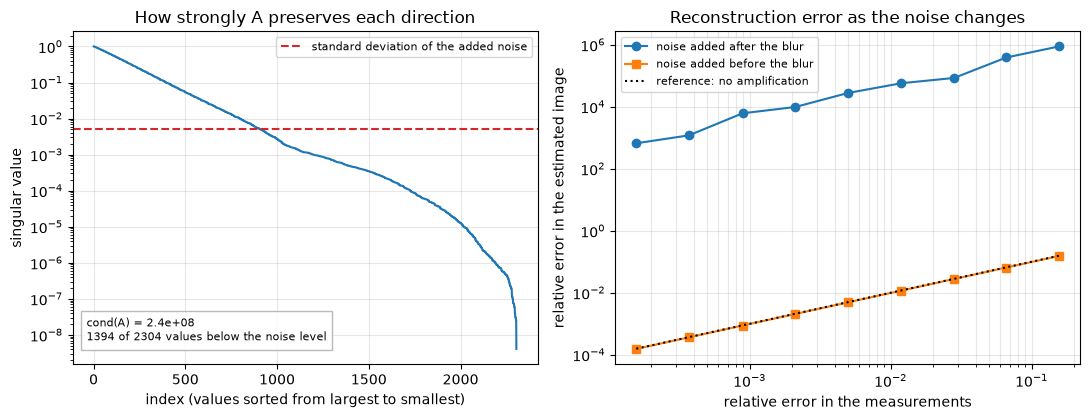

In [11]:
fig, (ax_spectrum, ax_noise) = plt.subplots(1, 2, figsize=(11, 4.3))

# Left panel: singular values from largest to smallest.
indices = np.arange(1, N + 1)
ax_spectrum.semilogy(indices, s, lw=1.5)
ax_spectrum.axhline(SIGMA_ETA, color="tab:red", ls="--",
                    label="standard deviation of the added noise")
ax_spectrum.set_xlabel("index (values sorted from largest to smallest)")
ax_spectrum.set_ylabel("singular value")
ax_spectrum.set_title("How strongly A preserves each direction")
ax_spectrum.grid(alpha=0.3)
ax_spectrum.legend(fontsize=8)
small_count = np.sum(s < SIGMA_ETA)
ax_spectrum.text(0.03, 0.06,
                 f"cond(A) = {s[0] / s[-1]:.1e}\n"
                 f"{small_count} of {N} values below the noise level",
                 transform=ax_spectrum.transAxes, fontsize=8, va="bottom",
                 bbox=dict(fc="white", ec="0.7", alpha=0.9))

# Right panel: repeat with several noise sizes and compare the errors.
noise_levels = np.logspace(-4, -1, 9)
repetitions = 5
relative_data_error = np.zeros((repetitions, len(noise_levels)))
relative_error_after = np.zeros_like(relative_data_error)
relative_error_before = np.zeros_like(relative_data_error)
rng_sweep = np.random.default_rng(7)

for level_index, noise_std in enumerate(noise_levels):
    for repetition in range(repetitions):
        trial_noise = noise_std * rng_sweep.standard_normal(N)
        relative_data_error[repetition, level_index] = (
            np.linalg.norm(trial_noise) / np.linalg.norm(y)
        )
        estimate_after = pseudoinverse_apply(y + trial_noise)
        estimate_before = pseudoinverse_apply(A @ (x + trial_noise))
        relative_error_after[repetition, level_index] = (
            np.linalg.norm(estimate_after - x) / np.linalg.norm(x)
        )
        relative_error_before[repetition, level_index] = (
            np.linalg.norm(estimate_before - x) / np.linalg.norm(x)
        )

mean_data_error = relative_data_error.mean(axis=0)
ax_noise.loglog(mean_data_error, relative_error_after.mean(axis=0), "o-",
                label="noise added after the blur")
ax_noise.loglog(mean_data_error, relative_error_before.mean(axis=0), "s-",
                label="noise added before the blur")
ax_noise.loglog(mean_data_error, mean_data_error, "k:",
                label="reference: no amplification")
ax_noise.set_xlabel("relative error in the measurements")
ax_noise.set_ylabel("relative error in the estimated image")
ax_noise.set_title("Reconstruction error as the noise changes")
ax_noise.grid(alpha=0.3, which="both")
ax_noise.legend(fontsize=8)

fig.tight_layout()



**Figure 2: how to read it.**

- **Left:** each point is a singular value. The smallest ones are at the bottom; when inverting, we divide by them and the noise can grow a lot. The red line indicates the standard deviation of the noise used in the first experiment.
- **Right:** the horizontal axis measures the relative error of the measurements and the vertical one the relative error of the reconstructed image. Both axes are logarithmic. The dotted diagonal represents a reference in which the error is not amplified. The curve for noise added after the blur lies far above it: the pseudoinverse amplifies that noise. The noise added before the blur stays close to the reference. Each point averages five random realizations.

**Key idea:** the blur hides details; the pseudoinverse tries to recover them, but it also amplifies the noise that occupies those same directions.



### Conclusions

1. **The pseudoinverse recovers the image when there is no noise**, with a very small numerical error.
2. **With noise added to the blurred measurement, the reconstruction can be very bad.** The pseudoinverse amplifies perturbations that the blur made hard to distinguish.
3. **The position of the noise matters:** when it is added before the blur, the ideal case behaves like recovering the original image plus that same noise.
4. **The lost information cannot be invented.** The pseudoinverse amplifies the noise that lies in the directions weakened by the blur, so a better prior, such as sparsity in a wavelet basis (Section 4.3), is needed to go further.



---

## 4.3 Exercise: denoising the blurred image with a sparse prior

In Section 3.1 we saw that inverting the blur directly amplifies the noise. Now we add an extra idea about what natural images are usually like: although they have many pixels, they can be described by a few large wavelet coefficients and many small ones. We call this property **sparsity** in the wavelet basis.

We look for an estimated image $\hat{x}$ that satisfies two goals:

$$\hat{x}=\arg\min_x \underbrace{\frac{1}{2}\|Ax-y_\eta\|_2^2}_{\text{fit the data}}+\lambda\underbrace{\|Wx\|_1}_{\text{favor few large wavelet coefficients}}.$$

- The first term asks that, after blurring the estimate, $A\hat{x}$ resembles the noisy measurement $y_\eta$.
- $W$ transforms the image into wavelet coefficients. $\|Wx\|_1$ sums their absolute values and favors many of them being small or zero.
- $\lambda$ controls the balance: a larger value removes more coefficients (and noise), but it can also erase details.

We use **ISTA**, an algorithm that repeats two steps: first it corrects the image so that its blurred data approach the measurement; then it applies a soft threshold to the small wavelet coefficients. The threshold keeps the large coefficients, associated with structure and edges, and reduces the small ones, which are often noise.

### 1. Wavelet transform, Lipschitz constant and thresholding


orthonormality: | ||Wv|| - ||v|| | = 7.1e-15, max|W^-1 W v - v| = 1.6e-15
coefficients for 95% of the energy: 38 of 2304
coefficients for 99% of the energy: 163 of 2304
fraction of coefficients with |c| < 1e-3: 16.1%
L = ||A^T A||_2 ~ 0.9912, step eta = 1/L = 1.0089


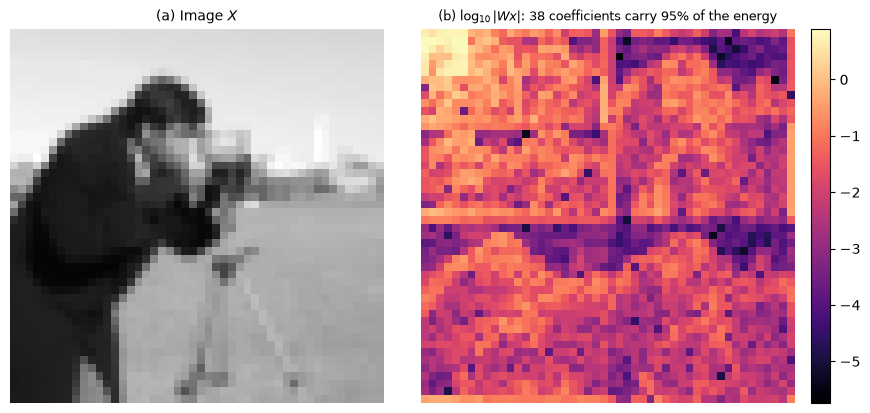

In [12]:
import pywt

# W turns the image into wavelet coefficients; Winv goes back to the image.
# db2 is the wavelet family and we use three decomposition levels.
WAVELET, LEVEL = "db2", 3
coeffs = pywt.wavedec2(X, wavelet=WAVELET, level=LEVEL, mode="periodization")
coeff_arr, coeff_slices = pywt.coeffs_to_array(coeffs)


def W(z):
    """Convert a pixel vector to a wavelet-coefficient vector."""
    C = pywt.wavedec2(z.reshape(h, w), wavelet=WAVELET, level=LEVEL,
                        mode="periodization")
    return pywt.coeffs_to_array(C)[0].ravel()


def Winv(u):
    """Reconstruct the pixel vector from the wavelet coefficients."""
    C = pywt.array_to_coeffs(u.reshape(coeff_arr.shape), coeff_slices,
                                output_format="wavedec2")
    return pywt.waverec2(C, wavelet=WAVELET, mode="periodization").ravel()


# Check that W preserves the length and that Winv undoes W.
v = np.random.default_rng(0).standard_normal(N)
print(f"orthonormality: | ||Wv|| - ||v|| | = "
        f"{abs(np.linalg.norm(W(v)) - np.linalg.norm(v)):.1e}, "
        f"max|W^-1 W v - v| = {np.abs(Winv(W(v)) - v).max():.1e}")

# Check sparsity: how many coefficients concentrate the image energy?
c = W(x)
energy = np.sort(c**2)[::-1]
cum = np.cumsum(energy) / energy.sum()
print(f"coefficients for 95% of the energy: {np.searchsorted(cum, 0.95) + 1} of {N}")
print(f"coefficients for 99% of the energy: {np.searchsorted(cum, 0.99) + 1} of {N}")
print(f"fraction of coefficients with |c| < 1e-3: {np.mean(np.abs(c) < 1e-3):.1%}")


# Compute L, a scale of the problem, with power iteration.
# The step size eta=1/L helps to keep the ISTA updates stable.
def power_iteration(M, n_iter=60):
    v = np.random.default_rng(1).standard_normal(M.shape[1])
    v /= np.linalg.norm(v)
    for _ in range(n_iter):
        v = M.T @ (M @ v)
        v /= np.linalg.norm(v)
    return v @ (M.T @ (M @ v))


L = power_iteration(A)
eta = 1.0 / L
print(f"L = ||A^T A||_2 ~ {L:.4f}, step eta = 1/L = {eta:.4f}")


def soft(u, alpha):
    """Shrink small coefficients toward zero and set those below alpha to zero."""
    return np.sign(u) * np.maximum(np.abs(u) - alpha, 0.0)


# Compare the original image with the size of its wavelet coefficients.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2))

ax1.imshow(X, cmap="gray", vmin=0, vmax=1)
ax1.set_title("(a) Image $X$", fontsize=10)
ax1.axis("off")

# The logarithm makes large and very small coefficients visible together.
im = ax2.imshow(np.log10(np.abs(coeff_arr) + 1e-6), cmap="magma")
ax2.set_title(f"(b) $\\log_{{10}}|Wx|$: {np.searchsorted(cum, 0.95) + 1} "
                f"coefficients carry 95% of the energy", fontsize=9)
ax2.axis("off")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

fig.tight_layout()



**Figure 3: how to read it.** The image is on the left. On the right, the absolute values of its wavelet coefficients are shown on a logarithmic scale (which is why both large and small ones are visible). The brightest areas correspond to coefficients of larger magnitude.

The plot and the printed numbers show that a small fraction of the coefficients concentrates most of the image energy. This justifies the sparse prior: we can try to remove small wavelet coefficients to reduce the noise while keeping the large ones that represent the main structure.

### 2. Choosing the regularization strength $\lambda$

We try several values of $\lambda$ and run ISTA for 250 iterations for each one. We compare the reconstructions with the original image using PSNR and SSIM. In a real problem we usually do not know the original image; here we can use it because we are doing a controlled experiment.


In [13]:
def ista(lam, n_iter, track=False):
    """Solve the model with ISTA for a given lambda and number of iterations."""
    # Start from a completely black image (all pixels zero).
    xk = np.zeros(N)
    hist = {"it": [], "psnr": [], "ssim": [], "obj": []}
    best = {"it": 0, "psnr": -np.inf, "ssim": 0.0, "x": None}

    for it in range(1, n_iter + 1):
        # Step 1: measure the prediction error A@xk - y_eta and correct xk.
        # A.T carries that correction from measurement space to image space.
        z = xk - eta * (A.T @ (A @ xk - y_eta))
        # Step 2: go to wavelets, shrink small coefficients and return to pixels.
        xk = Winv(soft(W(z), eta * lam))

        # Record metrics every 10 steps only when we want to track the evolution.
        if track and (it == 1 or it % 10 == 0):
            r = A @ xk - y_eta
            p = psnr(X, xk.reshape(h, w), data_range=1.0)
            q = ssim(X, xk.reshape(h, w), data_range=1.0)
            hist["it"].append(it)
            hist["psnr"].append(p)
            hist["ssim"].append(q)
            # Objective that ISTA tries to minimize: data error + wavelet penalty.
            hist["obj"].append(0.5 * r @ r + lam * np.abs(W(xk)).sum())
            # Also store the iteration with the best PSNR for this simulation.
            if p > best["psnr"]:
                best = {"it": it, "psnr": p, "ssim": q, "x": xk.copy()}

    return xk, hist, best


# Lambda values: we sweep from weak to strong regularization.
LAMBDAS = np.array([1e-5, 2e-5, 3e-5, 5e-5, 1e-4, 3e-4, 1e-3])
N_ITER_SWEEP = 250

# Run each configuration and record the final reconstruction quality.
sweep = []
for lam in LAMBDAS:
    xh, _, _ = ista(lam, N_ITER_SWEEP)
    sweep.append((lam,
                    psnr(X, xh.reshape(h, w), data_range=1.0),
                    ssim(X, xh.reshape(h, w), data_range=1.0)))

print(f"{'lambda':>8s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 28)
for lam, p, q in sweep:
    print(f"{lam:8.0e} {p:10.2f} {q:7.3f}")

best_lam = max(sweep, key=lambda row: row[1])[0]
print(f"\nBest lambda by PSNR: {best_lam:.1e}")


  lambda  PSNR (dB)    SSIM
----------------------------
   1e-05      28.05   0.874
   2e-05      28.05   0.877
   3e-05      28.05   0.879
   5e-05      28.02   0.883
   1e-04      27.85   0.886
   3e-04      26.98   0.877
   1e-03      25.58   0.853

Best lambda by PSNR: 2.0e-05



**What this comparison tells us:** with a very small $\lambda$, the algorithm barely penalizes the small coefficients and more noise remains. Increasing $\lambda$ removes more noise, but if it is too large, textures and details also disappear. The best value offers a balance. PSNR measures the average pixel error; SSIM focuses more on structural similarity, so their best values do not necessarily coincide.

### 3. Choosing when to stop ISTA

We fix the $\lambda$ that gave the best PSNR in the previous test and observe the algorithm for more iterations. We record the image quality and the value of the objective every 10 iterations. This reveals something important: the objective can keep decreasing even though the similarity to the true image has already started to worsen.


ISTA: lambda = 2.0e-05
best iteration =  260   PSNR = 28.05 dB   SSIM = 0.876
last iterate (1500 iterations): PSNR = 26.17 dB, SSIM = 0.752


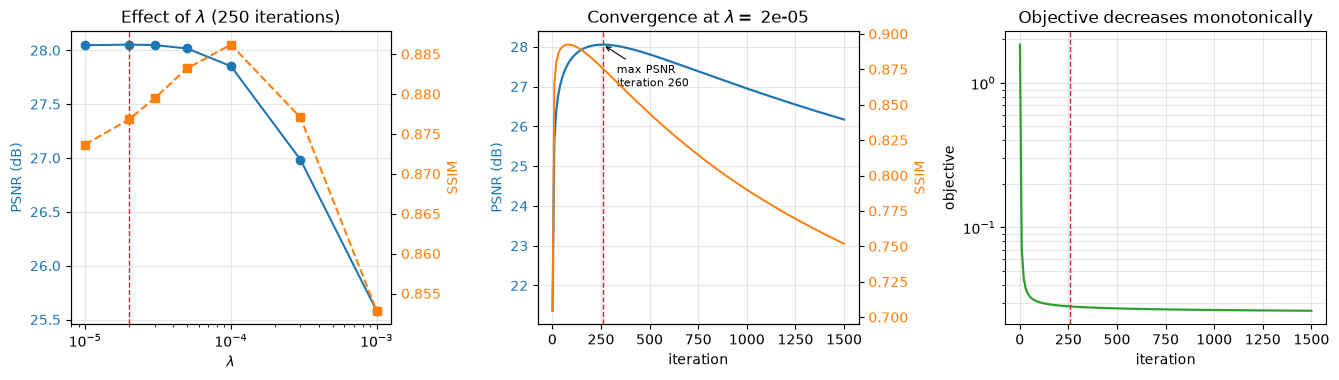

In [14]:
# Follow the optimization for more steps to observe its evolution.
N_ITER_MAX = 1500
x_last, hist, best = ista(best_lam, N_ITER_MAX, track=True)

# best contains the reconstruction with the best PSNR observed during the run.
best_it = best["it"]
x_ista = best["x"]

print(f"ISTA: lambda = {best_lam:.1e}")
print(f"best iteration = {best_it:4d}   PSNR = {best['psnr']:.2f} dB   "
      f"SSIM = {best['ssim']:.3f}")
print(f"last iterate ({N_ITER_MAX} iterations): "
      f"PSNR = {hist['psnr'][-1]:.2f} dB, SSIM = {hist['ssim'][-1]:.3f}")

lams_sweep = np.array([row[0] for row in sweep])
psnr_sweep = np.array([row[1] for row in sweep])
ssim_sweep = np.array([row[2] for row in sweep])

# Three panels: effect of lambda, quality during the iterations and objective.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# (a) Each curve shows how PSNR and SSIM change with lambda.
ax = axes[0]
ax.semilogx(lams_sweep, psnr_sweep, "o-", color="tab:blue")
ax.axvline(best_lam, color="tab:red", ls="--", lw=1)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Effect of $\lambda$ (250 iterations)")
ax_b = ax.twinx()
ax_b.semilogx(lams_sweep, ssim_sweep, "s--", color="tab:orange")
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")

# (b) Check whether the image keeps improving as the iterations advance.
ax = axes[1]
ax.plot(hist["it"], hist["psnr"], color="tab:blue", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Convergence at $\lambda=$" + f" {best_lam:.0e}")
ax_b = ax.twinx()
ax_b.plot(hist["it"], hist["ssim"], color="tab:orange", lw=1.4)
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")
ax.annotate(f"max PSNR\niteration {best_it}", (best_it, best["psnr"]),
            textcoords="offset points", xytext=(10, -30), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8))

# (c) The mathematical objective that ISTA minimizes should keep decreasing.
ax = axes[2]
ax.semilogy(hist["it"], hist["obj"], color="tab:green", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("objective")
ax.set_title("Objective decreases monotonically")
ax.grid(alpha=0.3, which="both")

fig.tight_layout()



**Figure 4: how to read it.**

- **Panel (a):** quality versus $\lambda$ after 250 iterations. Blue = PSNR; orange = SSIM. The red vertical line indicates the $\lambda$ chosen by PSNR. The metrics may prefer slightly different values because they measure different things.
- **Panel (b):** PSNR and SSIM during the iterations, using that $\lambda$. The red line marks the iteration with the highest PSNR. If the quality drops afterwards, it means that more iterations are fitting details of the noise.
- **Panel (c):** value of the objective that ISTA minimizes. That it keeps decreasing means the algorithm is optimizing its formula, but it does not guarantee that the image resembles the true one more and more.

That is why stopping the algorithm early also helps to regularize: it is not always best to run the largest possible number of iterations. The best $\lambda$ and the best iteration are identified using the known original image; with real data they would have to be chosen without that reference.



### 4. Comparison with the direct inversion

We now compare ISTA at its best configuration against the blurred data and the direct pseudoinverse from Section 3.1.


method                    PSNR (dB)    SSIM
--------------------------------------------
blurred measurement           23.49   0.812
direct inversion             -86.90   0.000
ISTA, 10 iterations           25.64   0.865
ISTA, 260 iterations          28.05   0.876


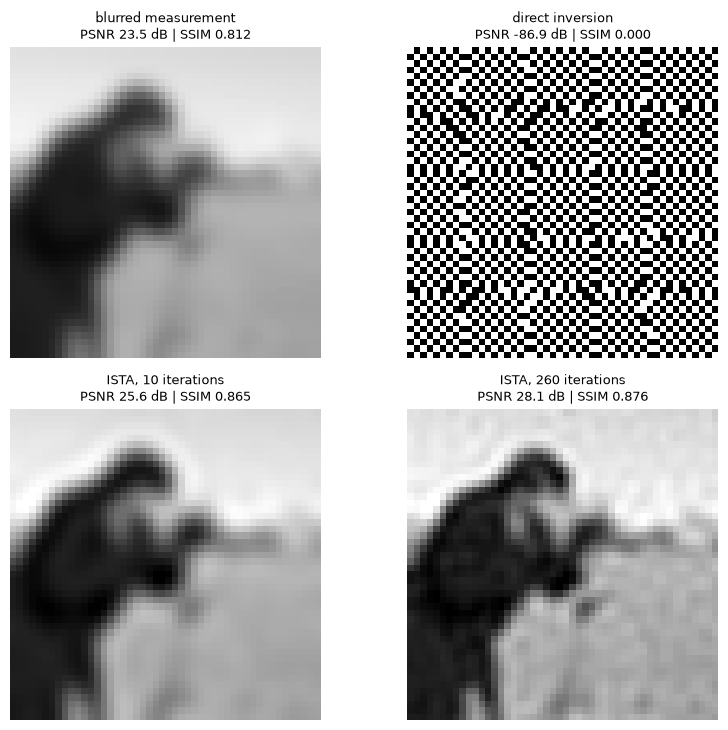

In [15]:
xh10, _, _ = ista(best_lam, 10)

methods = [
    ("blurred measurement", y),
    ("direct inversion", x_recovered_noisy),
    ("ISTA, 10 iterations", xh10),
    (f"ISTA, {best_it} iterations", x_ista),
]

print(f"{'method':24s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 44)
for name, z in methods:
    Z = z.reshape(h, w)
    print(f"{name:24s} {psnr(X, Z, data_range=1.0):10.2f} "
            f"{ssim(X, Z, data_range=1.0):7.3f}")

# Arrange the four reconstructions in a 2 x 2 grid.
fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.4))

for ax, (name, z) in zip(axes.ravel(), methods):
    Z = z.reshape(h, w)
    p = psnr(X, Z, data_range=1.0)
    q = ssim(X, Z, data_range=1.0)
    # Clipping to [0, 1] only affects the display, not the metrics.
    ax.imshow(np.clip(Z, 0, 1), cmap="gray", vmin=0, vmax=1,
                interpolation="nearest", aspect="equal")
    ax.set_title(f"{name}\nPSNR {p:.1f} dB | SSIM {q:.3f}", fontsize=9)
    ax.axis("off")

fig.tight_layout()



**Figure 5.** From top-left to bottom-right: the blurred measurement, the unstable direct inversion, ISTA after only 10 iterations, and ISTA at its best iteration. ISTA removes most of the noise of the direct inversion while keeping the main edges; the residual error is mostly the information that the blur destroyed.

### Conclusions for this exercise

1. **Without a prior, the inversion amplifies noise.** The direct pseudoinverse gives PSNR $-86.9$ dB, a completely unusable image. The wavelet prior suppresses most of that noise because it forces the solution to be sparse in a basis where the image is concentrated in a few coefficients.
2. **Soft-thresholding is the prior in action.** Small wavelet coefficients are dominated by noise and are set to zero; large coefficients carry edges and texture and are only shrunk by $\eta\lambda$. That is why the reconstruction keeps structure while removing high-frequency noise.
3. **$\lambda$ controls the bias-variance tradeoff.** Too small ($\lesssim10^{-5}$) leaves noise; too large ($\gtrsim3\times10^{-4}$) over-smooths and erases texture. PSNR is flat over a decade of useful values, while SSIM prefers slightly stronger regularization.
4. **Iterations also regularize.** The objective decreases monotonically, but PSNR peaks at about 260 iterations and then declines (26.2 dB at 1500). Solving the model too accurately overfits the noise, so early stopping is a second regularization knob. A faster alternative is FISTA, which reaches a similar point in far fewer iterations.
5. **The gain is substantial.** ISTA reaches $28.05$ dB and SSIM $0.876$, against $-86.9$ dB for the direct inversion. Since 1394 singular directions are already below the noise level, no method can recover that information; the prior improves the structure, not the missing frequencies.
6. **Other priors.** A total-variation prior would favor piecewise-smooth images and preserve sharp edges better, at the cost of a more involved proximal step (Chambolle's algorithm) and possible staircasing. Learned priors (denoisers, networks) can capture richer image statistics than a fixed wavelet basis.
